In [61]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.ticker as ticker
from scipy.interpolate import make_interp_spline as mis

Оценка фазовой и групповой скорости

Синусоидальный сигнал

In [62]:
n = np.arange(1, 8) #от 1 до 7

v_1 = np.array([3.96, 7.98, 11.99, 15.97, 20.01, 24.02, 28.06]) #согласованная линия
v_2 = np.array([3.8, 7.7, 11.6, 15.4, 19.3, 23.2, 27.1]) #без нагрузки

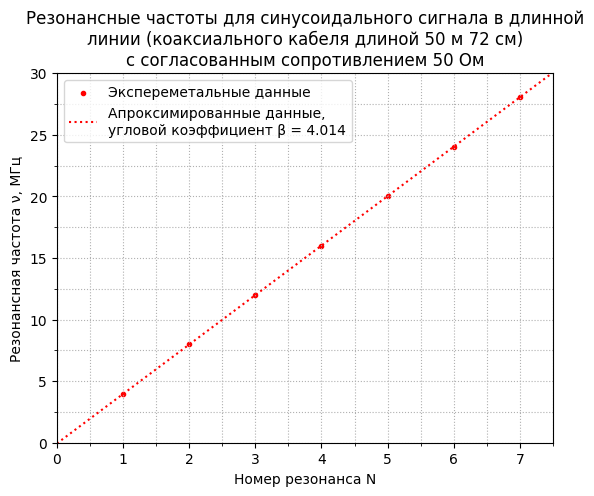

In [63]:
ax = plt.gca()
plt.scatter(n, v_1, marker='.', label='Экспереметальные данные', color='red')
coeffs = np.polyfit(n, v_1, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 8, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент β = {coeffs[0]:.3f}", color='red', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(2.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 30)
plt.xlim(0, 7.5)
plt.title('Резонансные частоты для синусоидального сигнала в длинной\nлинии (коаксиального кабеля длиной 50 м 72 см)\nс согласованным сопротивлением 50 Ом')
plt.xlabel("Номер резонанса N")
plt.ylabel("Резонансная частота ν, МГц")
ax.legend()
plt.show()

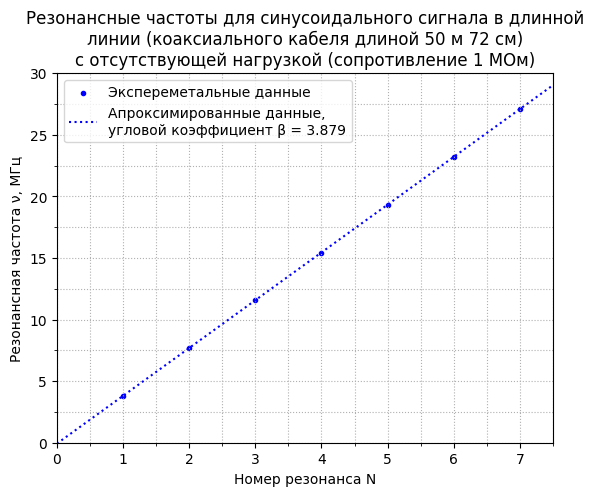

In [64]:
ax = plt.gca()
plt.scatter(n, v_2, marker='.', label='Экспереметальные данные', color='blue')
coeffs = np.polyfit(n, v_2, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 8, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент β = {coeffs[0]:.3f}", color='blue', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(2.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 30)
plt.xlim(0, 7.5)
plt.title('Резонансные частоты для синусоидального сигнала в длинной\nлинии (коаксиального кабеля длиной 50 м 72 см)\nс отсутствующей нагрузкой (сопротивление 1 МОм)')
plt.xlabel("Номер резонанса N")
plt.ylabel("Резонансная частота ν, МГц")
ax.legend()
plt.show()

Прямоугольные импульсы

In [65]:
n = np.arange(1, 8) #от 1 до 7

v_1 = np.array([4.01, 8.02, 12.03, 16.04, 20.05, 24.06, 28.07]) #согласованная линия
v_2 = np.array([3.91, 7.83, 11.76, 15.64, 19.6, 23.52, 27.43]) #без нагрузки

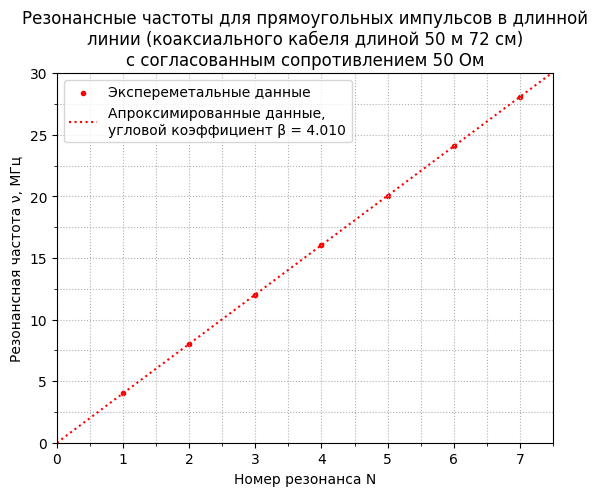

In [66]:
ax = plt.gca()
plt.scatter(n, v_1, marker='.', label='Экспереметальные данные', color='red')
coeffs = np.polyfit(n, v_1, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 8, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент β = {coeffs[0]:.3f}", color='red', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(2.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 30)
plt.xlim(0, 7.5)
plt.title('Резонансные частоты для прямоугольных импульсов в длинной\nлинии (коаксиального кабеля длиной 50 м 72 см)\nс согласованным сопротивлением 50 Ом')
plt.xlabel("Номер резонанса N")
plt.ylabel("Резонансная частота ν, МГц")
ax.legend()
plt.show()

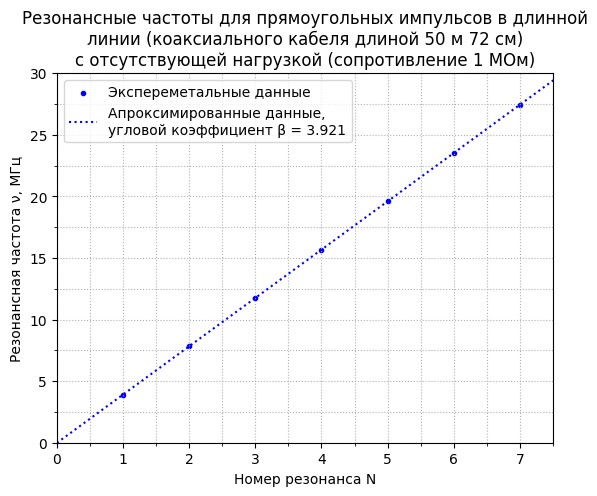

In [67]:
ax = plt.gca()
plt.scatter(n, v_2, marker='.', label='Экспереметальные данные', color='blue')
coeffs = np.polyfit(n, v_2, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 8, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент β = {coeffs[0]:.3f}", color='blue', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(2.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 30)
plt.xlim(0, 7.5)
plt.title('Резонансные частоты для прямоугольных импульсов в длинной\nлинии (коаксиального кабеля длиной 50 м 72 см)\nс отсутствующей нагрузкой (сопротивление 1 МОм)')
plt.xlabel("Номер резонанса N")
plt.ylabel("Резонансная частота ν, МГц")
ax.legend()
plt.show()

АЧХ И ФЧХ

In [68]:
l = 5072.2
v = np.array([1, 3, 6, 9, 10, 12, 15, 17, 21, 23, 26, 28, 30, 33, 35, 37, 38, 40])
dx = np.array([252, 253, 84.8, 28.8, 50.2, 0.8, 50.2, 14.7, 12, 32, 18.7, 35.3, 16, 6.7, 20.5, 6.1, 12.24, 23.96])
u0 = np.array([26.6, 26.6, 26.2, 26.4, 26.2, 26.2, 26.2, 26.2, 26.2, 26, 25.8, 25.8, 25.8, 25.8, 25.8, 25.8, 25.8, 25.8])
uh = np.array([25, 24.4, 23.4, 22.2, 22.2, 21.8, 21.2, 20.4, 20, 20, 20, 19.6, 19.6, 19.2, 19.2, 18.8, 18.8, 18.8])
N = np.array([0, 0, 1, 2, 2, 3, 3, 4, 5, 5, 6, 6, 7, 8, 8, 9, 9, 9])
dfi = (v*dx*10**(-3)+N)*2
a = np.log(u0/uh)/l
k = dfi*np.pi/l
X = (v*10**6*2*np.pi)**2
Y = k**2 - a**2

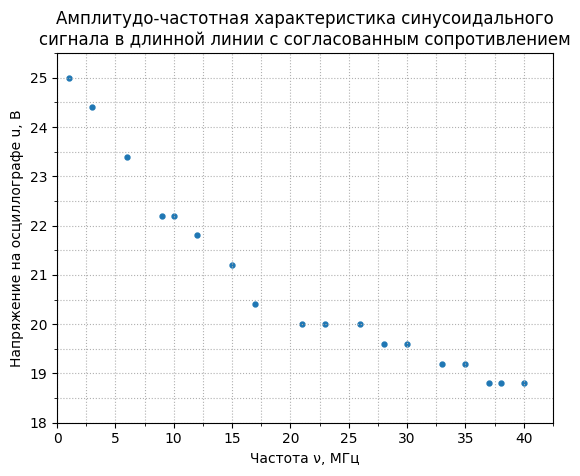

In [69]:
plt.scatter(v, uh, s=50, marker='.')
ax = plt.gca()
ax.xaxis.set_minor_locator(ticker.MultipleLocator(2.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(18, 25.5)
plt.xlim(0, 42.5)
plt.title('Амплитудо-частотная характеристика синусоидального\nсигнала в длинной линии с согласованным сопротивлением')
plt.xlabel("Частота ν, МГц")
plt.ylabel("Напряжение на осциллографе u, В")
plt.show()

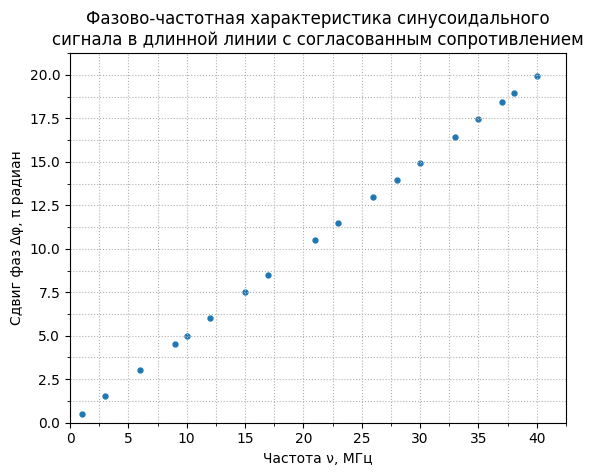

In [70]:
plt.scatter(v, dfi, s=50, marker='.')
ax = plt.gca()
ax.xaxis.set_minor_locator(ticker.MultipleLocator(2.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1.25))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 21.25)
plt.xlim(0, 42.5)
plt.title('Фазово-частотная характеристика синусоидального\nсигнала в длинной линии с согласованным сопротивлением')
plt.xlabel("Частота ν, МГц")
plt.ylabel("Сдвиг фаз Δφ, π радиан")
plt.show()

Определение параметров коаксиального кабеля

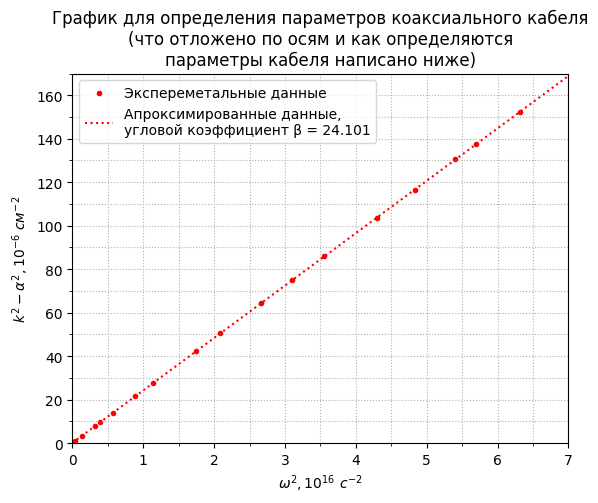

In [71]:
ax = plt.gca()
plt.scatter(X/10**16, Y*10**6, marker='.', label='Экспереметальные данные', color='red')
coeffs = np.polyfit(X/10**16, Y*10**6, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 7, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент β = {coeffs[0]:.3f}", color='red', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(10))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 170)
plt.xlim(0, 7)
plt.title('График для определения параметров коаксиального кабеля\n(что отложено по осям и как определяются\nпараметры кабеля написано ниже)')
plt.xlabel(r'$ω^2, 10^{16}\ с^{-2}$')
plt.ylabel(r'$k^2 - α^2, 10^{-6}\ см^{-2}$')
ax.legend()
plt.show()

Определение удельной проводимости проводников

Метод А

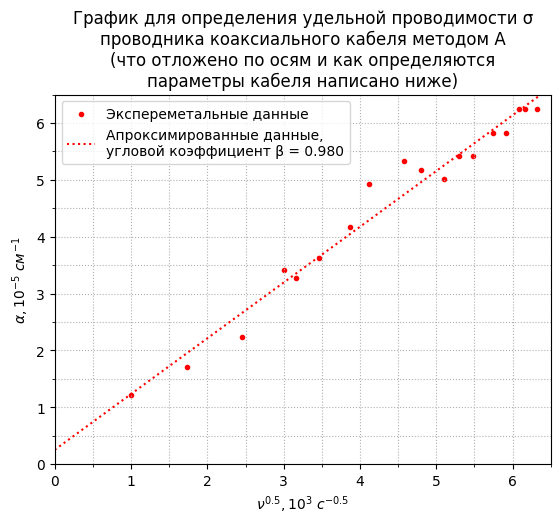

In [72]:
ax = plt.gca()
plt.scatter(np.sqrt(v*10**6)/10**3, a*10**5, marker='.', label='Экспереметальные данные', color='red')
coeffs = np.polyfit(np.sqrt(v*10**6)/10**3, a*10**5, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 6.5, 1000)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент β = {coeffs[0]:.3f}", color='red', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.5))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 6.5)
plt.xlim(0, 6.5)
plt.title('График для определения удельной проводимости σ\nпроводника коаксиального кабеля методом А\n(что отложено по осям и как определяются\nпараметры кабеля написано ниже)')
plt.xlabel(r'$ν^{0.5}, 10^{3}\ с^{-0.5}$')
plt.ylabel(r'$α, 10^{-5}\ см^{-1}$')
ax.legend()
plt.show()

Метод Б

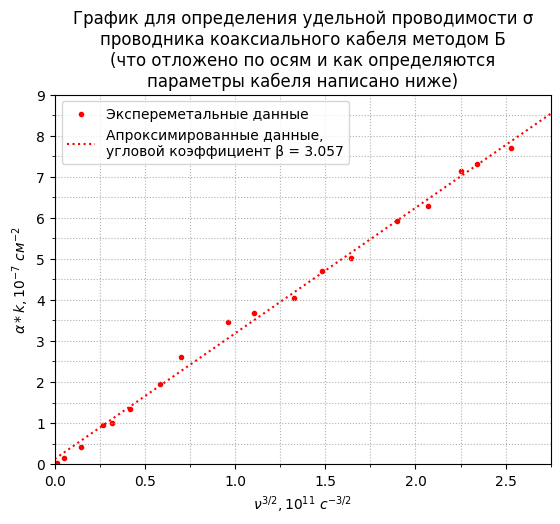

In [73]:
ax = plt.gca()
plt.scatter(np.pow(v*10**6, 3/2)/10**11, a*k*10**7, marker='.', label='Экспереметальные данные', color='red')
coeffs = np.polyfit(np.pow(v*10**6, 3/2)/10**11, a*k*10**7, deg=1)
poly_func = np.poly1d(coeffs)
x = np.linspace(0, 2.75, 100)
y = poly_func(x)
plt.plot(x, y, label=f"Апроксимированные данные,\nугловой коэффициент β = {coeffs[0]:.3f}", color='red', ls=':',)
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.25))  
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))
ax.grid(True, which='both', axis='both', linestyle='dotted')
plt.ylim(0, 9)
plt.xlim(0, 2.75)
plt.title('График для определения удельной проводимости σ\nпроводника коаксиального кабеля методом Б\n(что отложено по осям и как определяются\nпараметры кабеля написано ниже)')
plt.xlabel(r'$ν^{3/2}, 10^{11}\ с^{-3/2}$')
plt.ylabel(r'$α*k, 10^{-7}\ см^{-2}$')
ax.legend()
plt.show()